<a href="https://colab.research.google.com/github/muhammad-usman-tech/data-analysis-tasks/blob/main/Task_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

shape of the df is :  (48895, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12

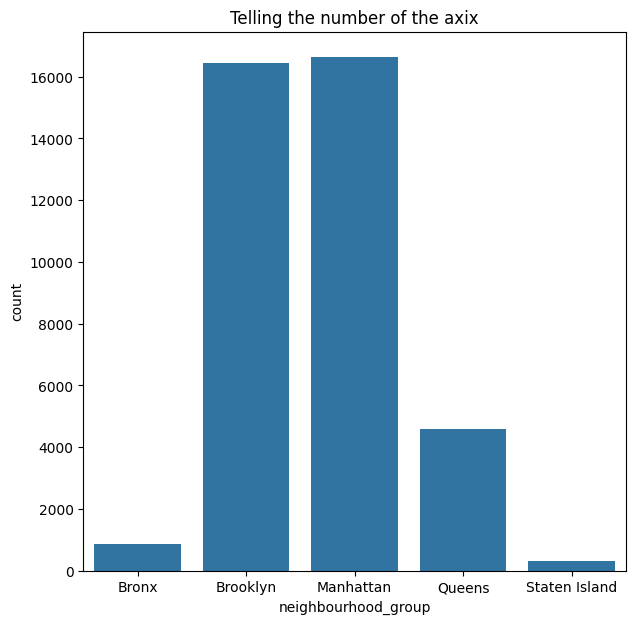

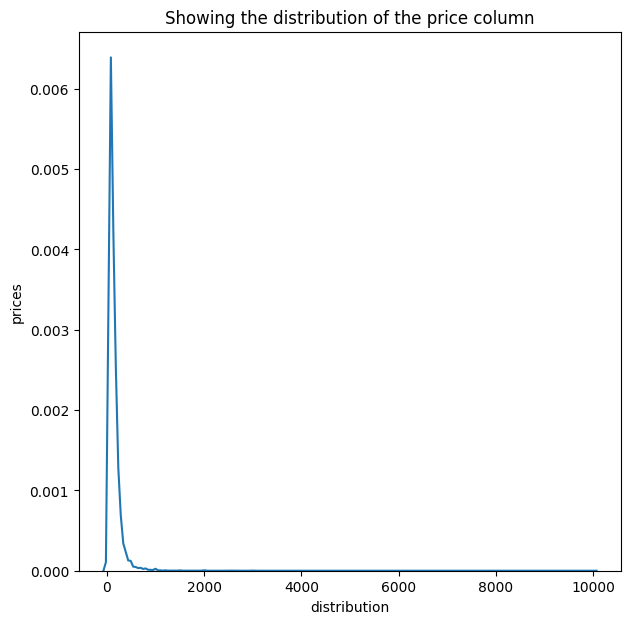

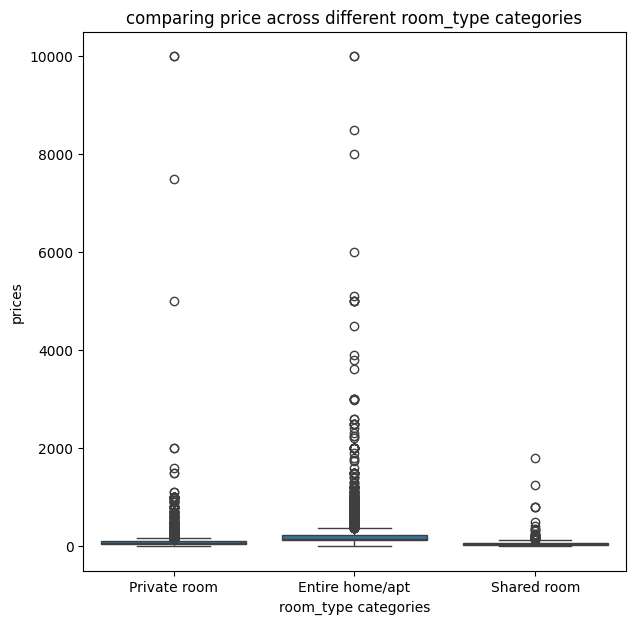

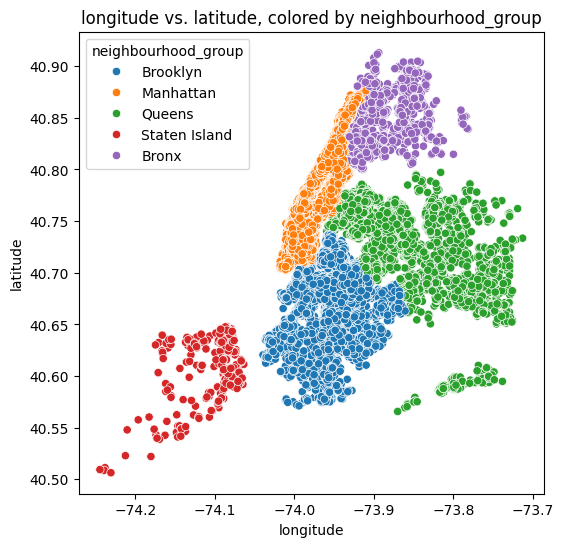

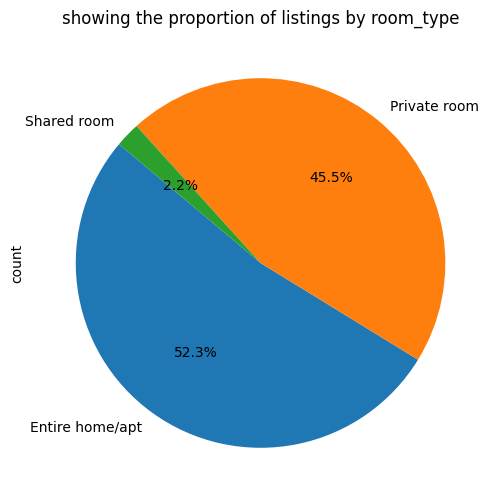

number_of_reviews                           \
room_type             Entire home/apt Private room Shared room   
neighbourhood_group                                              
Bronx                       37.627832    31.129771   10.046512   
Brooklyn                    32.720235    26.730014   19.975862   
Manhattan                   23.592555    33.151054   28.853933   
Queens                      34.812859    34.910821   18.059211   
Staten Island               39.046667    35.660377    2.800000   

                              price                           
room_type           Entire home/apt Private room Shared room  
neighbourhood_group                                           
Bronx                    120.789644    57.093511   56.930233  
Brooklyn                 171.249265    73.339797   45.458621  
Manhattan                230.190830   106.603265   77.980337  
Queens                   139.225603    69.286567   64.467105  
Staten Island            125.366667    57.584906   57.600000

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#104: loaded

df=pd.read_csv('/content/AB_NYC_2019.csv')
# 105:Perform EDA: shape, dtypes, missing values, descriptive statistics.
# according to me EDA stands for exploratery data analysis and in this we make the data ready for the aggregation phase

# shape
print('shape of the df is : ', df.shape)
#  we got 48 thousand and 8 hundred rows and the 16 attributes

# inspecting the datatypes
df.info()
df.head()
# ok so all the datatypes look quite good but the last_review 38843 non-null  object is something date and must be some date time
# try do it
df['last_review']=pd.to_datetime(df['last_review'],format='mixed')
# df.info() changed here

# now missing values i have to do and think it by my self and i have to think how can remove all the missing values and what can be the right approach
# firstly finding the percentage of the nulls then i will se what to do

null=df.isnull().sum()
per=(null/len(df))*100
per
# ok so last_review reviews_per_month have 22.55 percent
# we can also drop them but thats not a good way

drop_col=per[per>=50].index
drop_col
df=df.drop(columns=drop_col) # not column has more then 50 percent

# ok now filling each by their data types
#start with numeric(int and float)
num_col=df.select_dtypes(include=['number']).columns

num_col
df[num_col]=df[num_col].fillna(df[num_col].median())
# here now move to the object and the string

obj_col=df.select_dtypes(include=['object']).columns
obj_col
df[obj_col]=df[obj_col].fillna(df[obj_col].mode().iloc[0])
# done now go for the date and time

# date_time_col=df.select_dtypes(include=['datetime']).columns
# date_time_col
# df[date_time_col]=df[date_time_col].fillna(df[date_time_col].mode().iloc[0])
df.dropna(subset=['last_review'],inplace=True)
# done now check the percentage again

print('null values final check : ',(df.isnull().sum()/len(df))*100) #yes now all is 0(zero)

# now last descriptive statistics
statistics=df.describe(include='all')
statistics
df.to_csv('cleaned_df.csv')
#step 105 done by my side

# 106
data_bar=df.groupby('neighbourhood_group')['neighbourhood_group'].value_counts()

data_bar
plt.figure(figsize=(7,7))
sns.barplot(x=data_bar.index,y=data_bar.values)
plt.title('Telling the number of the axix')
plt.xlabel('neighbourhood_group')
plt.ylabel('count')
plt.show()
# interpretation: it is observed that the that 90 percent of the groups are brooklyn and manhattan which are indivisually almost 16000 and others groups are combined almost 5500



# 107:Create a histogram showing the distribution of price. Apply a log scale to the x-axis and
# explain why this is appropriate.
plt.figure(figsize=(7,7))
# with the log_scale=True it is some thing else to understand first of all just let me understand this simple histplot
sns.kdeplot(data=df['price'])
# can also use the histplot instead of the kde
plt.title('Showing the distribution of the price column')
plt.xlabel('distribution')
plt.ylabel('prices')
plt.show()

# interpretation: ok so it is observed from the kernal density plot that almost all prices of the rooms are less and only few prices are very high like more then the 2000,basically in the histplot there were very close lins on the 0 and upto almost 1000 so some times kde is easy to tell what you have understood

# 108:Create a box plot comparing price across different room_type categories.


plt.figure(figsize=(7,7))
sns.boxplot(x=df['room_type'],y=df['price'],data=df)
plt.title('comparing price across different room_type categories')
plt.xlabel('room_type categories')
plt.ylabel('prices')
plt.show()
# interetation: there were 3 room types and the prices of all the types of rooms are so close and show alot of noisy daya outer then the maximum wick all the median and the Q1 and the Q3 are almost very close in the all types of rooms


#109: Create a scatter plot of longitude vs. latitude, colored by neighbourhood_group, to
# visualize geographic clustering of listings.

plt.figure(figsize=(6,6))
sns.scatterplot(x=df['longitude'],y=df['latitude'],data=df,hue=df['neighbourhood_group'])
plt.title('longitude vs. latitude, colored by neighbourhood_group')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

# interpretation: it is truely observed that the there is no such strong relation is found between these 2 columns it was just a little weak relation(i also checked it by the regplot that showed a line)


# 110: Create a pie chart showing the proportion of listings by room_type.

data=df['room_type'].value_counts()
data

plt.figure(figsize=(6,6))
data.plot.pie(autopct='%1.1f%%', startangle=140)
plt.title('showing the proportion of listings by room_type')
plt.show()
# interpretation:  thsi pie chart shows that only 2.2 percent peaople list the shared rooms other visiters 52 percent chose the complete home/apt and almost 45 percent people chose the private rooms

# in the middle line all are the kde's but with the opposite it is making the scatter plots because all were the numeric column's



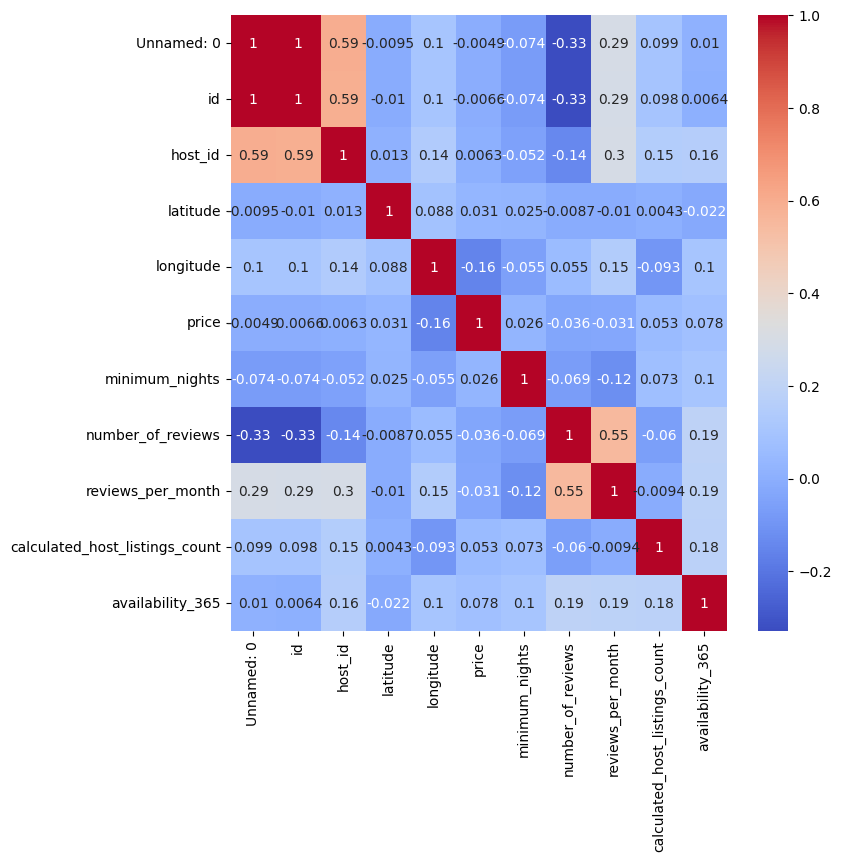

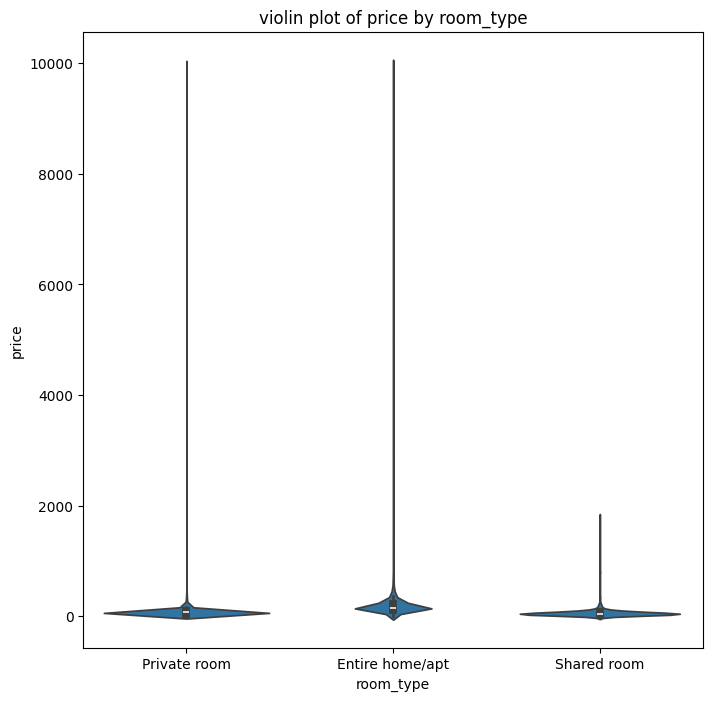

<Figure size 600x600 with 0 Axes>

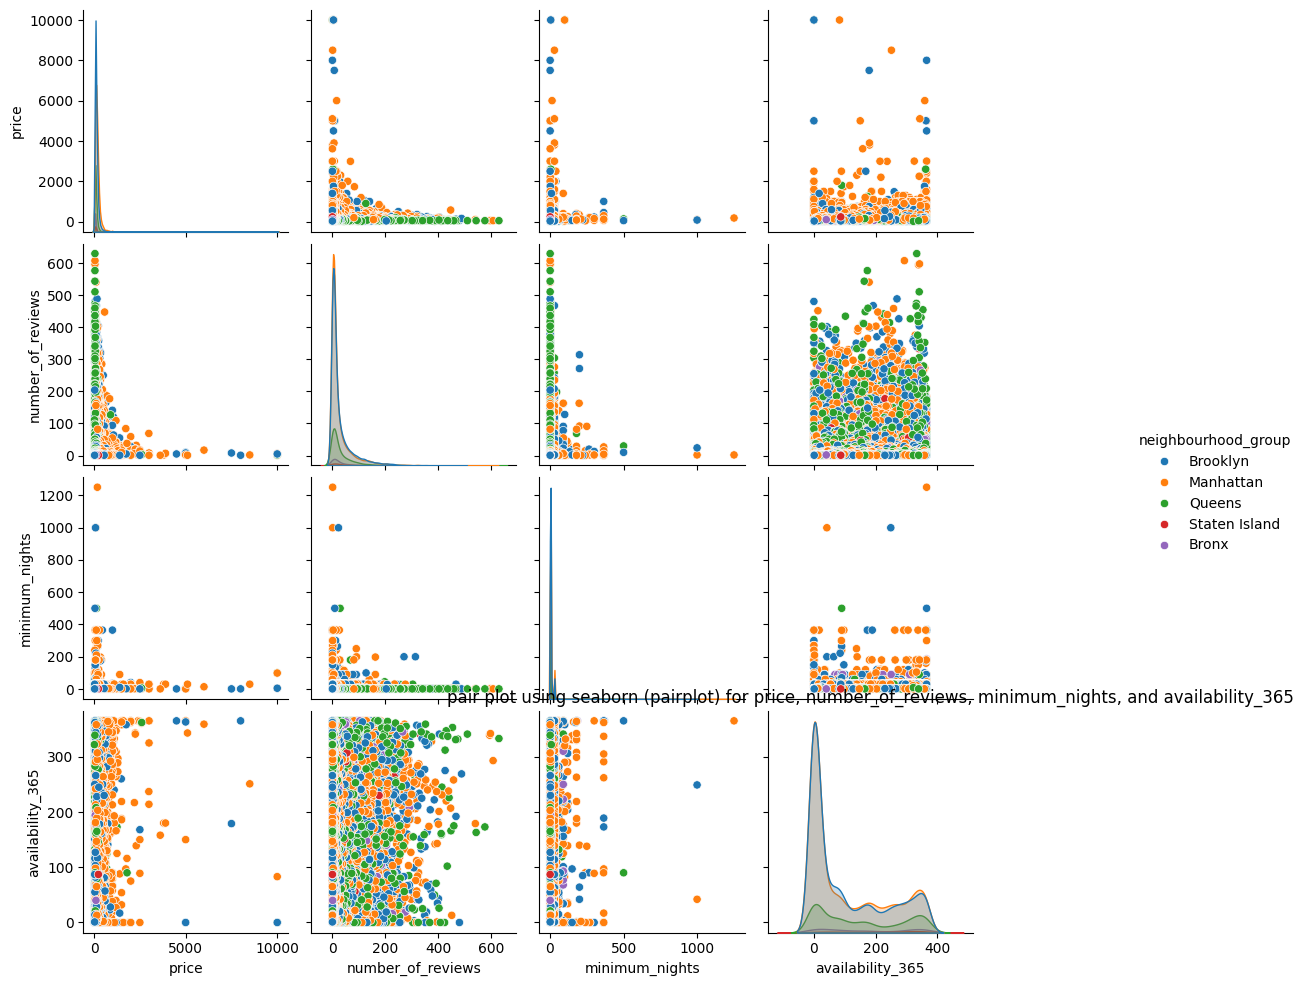

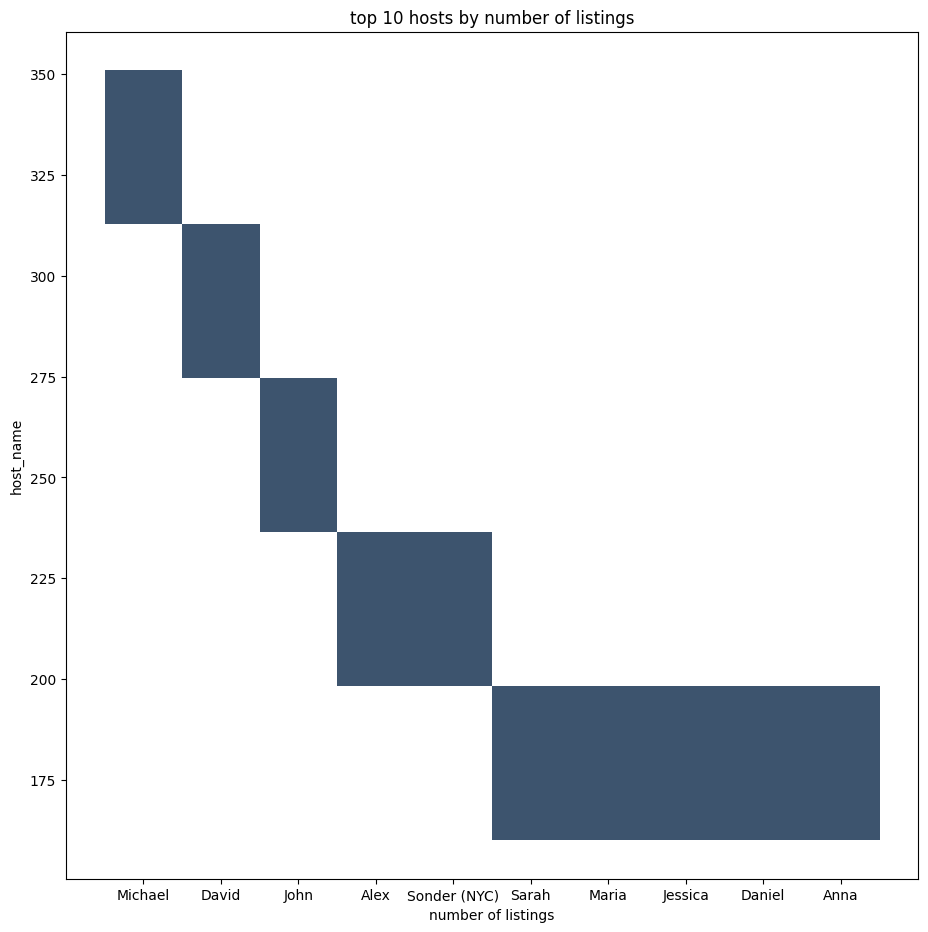

,Unnamed: 0,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
3,4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
4,5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,2019-06-22,0.59,1,129


In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# 112 : Load the cleaned Airbnb DataFrame from Task 14
df=pd.read_csv('/content/cleaned_df.csv')


# 113
# Create a correlation heatmap of all numerical columns
plt.figure(figsize=(8,8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')

# interpretation: ok so basically heatmaps shows the correlation between the different numeric columns and gere it is exactly showing th same thing some columns have weak relationa and some have strong relations like availability and latitide have very weak relation of -ve 0.022 like this

# 114:Create a violin plot of price by room_type.
plt.figure(figsize=(8,8))
sns.violinplot(x=df['room_type'],y=df['price'],data=df)
plt.title('violin plot of price by room_type')
plt.show()

# interpretation: ok so this violin plot shows the shape of the distributiona and it is showing that the almost all the room types violin is wider around 0-500 it means more rooms have the prices near 0-500 but the max prices of the private rooms and the full home/apt are indivisually very high

# 115:Create a pair plot using seaborn (pairplot) for price, number_of_reviews,
# minimum_nights, and availability_365. Color by neighbourhood_group.

df_pairplot=df[['price','number_of_reviews','minimum_nights','availability_365','neighbourhood_group']]
plt.figure(figsize=(6,6))
sns.pairplot(df_pairplot,hue='neighbourhood_group')
plt.title('pair plot using seaborn (pairplot) for price, number_of_reviews, minimum_nights, and availability_365')
plt.show()

# interpretation: what is the pairplor :as i gave it many columns and as its name represents it will make pair of every given columns with every given column and make the perfect pair between the atribute
# and here it is making the same thing some are the scatter plots and some are the kde's


# 116:create a grouped summary of average price and average
# number_of_reviews by neighbourhood_group AND room_type. Display as a pivot table.
pivot_data=df.pivot_table(index='room_type',columns='neighbourhood_group',aggfunc='mean',values=['number_of_reviews','price'])
pivot_data


# 117:Identify the top 10 hosts by number of listings. Create a horizontal bar chart.

top_10_hosts=df['host_name'].value_counts().head(10).sort_values(ascending=False)

plt.figure(figsize=(11,11))
sns.histplot(x=top_10_hosts.index,y=top_10_hosts.values)
plt.title('top 10 hosts by number of listings')
plt.xlabel('number of listings')
plt.ylabel('host_name')
plt.show()
# interpretation: it is observed from the histplot that the host name with the max listing is micheal and the last 3-4 host name for the top 10 listing have almost same number of listing that is from annah to sarah and that is almost 180 to 190
# almost done the other tasks were the instructions
